# Задача линейного программирования и симплекс-метод

**Вариант 4**

## Цель работы
Освоить решение задачи линейного программирования (ЛП) двумя способами:
перебором вершин допустимого множества и симплекс-методом; реализовать оба
алгоритма и сравнить их.

## Условие
$$z = c_1 x_1 + c_2 x_2 \to \max,$$
$$a_{11}x_1 + a_{12}x_2 \le b_1,\qquad a_{21}x_1 + a_{22}x_2 \le b_2,\qquad x_1, x_2 \ge 0.$$

Данные варианта 4: $c_1=5,\ c_2=-2,\ b_1=12,\ b_2=8,\ a_{11}=8,\ a_{12}=2,\ a_{21}=5,\ a_{22}=6$, то есть

$$z = 5x_1 - 2x_2 \to \max,\quad 8x_1 + 2x_2 \le 12,\quad 5x_1 + 6x_2 \le 8,\quad x_1, x_2 \ge 0.$$

В матричной (стандартной) форме: $c^T X \to \max,\ AX \le b,\ X \ge 0$, где
$$c=\begin{pmatrix}5\\-2\end{pmatrix},\quad
A=\begin{pmatrix}8&2\\5&6\end{pmatrix},\quad
b=\begin{pmatrix}12\\8\end{pmatrix},\quad X=\begin{pmatrix}x_1\\x_2\end{pmatrix}.$$

**Часть 1.** Решить задачу перебором вершин.
**Часть 2.** Решить задачу симплекс-методом.

- **Стандартная форма** ЛП: $c^T X \to \max,\ AX \le b,\ X \ge 0$,
  $A \in \mathbb{R}^{m\times n}$, $b \in \mathbb{R}^m$, $c \in \mathbb{R}^n$.
   Здесь $m=n=2$.
- **Допустимое множество** $G=\{X\in\mathbb{R}^n:\ AX\le b,\ X\ge 0\}$ —
  замкнутое выпуклое многогранное множество.
- **Вершина** $X^*\in G$: из $X^*=\lambda Y+(1-\lambda)Z$,
  $Y,Z\in G$, $0<\lambda<1$ следует $Y=Z=X^*$. Геометрически
  вершины двумерной области — точки пересечения её граничных прямых.
- **Теорема об оптимальной вершине**: если $G$ — непустое
  ограниченное многогранное множество, то $f(X)=c^TX$ достигает на $G$
  максимума и минимума, причём среди оптимальных решений есть вершина.
  Отсюда способ решения: достаточно сравнить значения $z$ в вершинах.
- **Каноническая форма**: $c^T X \to \max,\ AX=b,\ X\ge 0$.
  Неравенство $a_i^T X \le b_i$ превращается в равенство добавочной
  переменной $s_i = b_i - a_i^T X \ge 0$ (остаток ресурса).
- **Активное ограничение**: $s_i=0$ — решение лежит на граничной
  прямой; $s_i>0$ — ограничение неактивно. Вершина $X\in\mathbb{R}^2$ —
  это точка, где обращаются в нуль $n=2$ из $n+m=4$ переменных
  $(x_1,x_2,s_1,s_2)$ (две активные границы). Такие точки называют
  базисными решениями: вершине соответствует базисное решение.
- **Симплекс-метод** не перебирает все вершины, а использует
  геометрическую структуру $G$, переходя между **соседними** базисными
  решениями, пока значение $z$ можно увеличить.
- **Три исхода**: $G=\varnothing$; $z$ не ограничена сверху на
  $G$; оптимум существует.

## Часть 1. Перебор вершин

### Алгоритм
1. Записать все границы $G$ как $m+n$ прямых: $a_i^T X = b_i$
   ($i=1,\dots,m$) и $x_j=0$ ($j=1,\dots,n$). Для $m=n=2$ это 4 прямые.
2. Перебрать все наборы из $n=2$ прямых ($C_{m+n}^{n}=C_4^2=6$ наборов).
   Для каждого решить систему $2\times 2$ (если определитель равен нулю —
   прямые параллельны, вершины нет).
3. Проверить допустимость найденной точки: $AX\le b$, $X\ge 0$ (т.е. $X\in G$).
   Недопустимые точки отбросить.
4. В каждой допустимой вершине вычислить $z=c^TX$.
5. Оптимальная вершина — с наибольшим $z$ (по теореме об оптимальной
   вершине, $G$ здесь непусто ($O\in G$) и ограничено).

In [8]:
import itertools
import numpy as np
import pandas as pd

eps = 1e-9

c = np.array([5.0, -2.0])          
A = np.array([[8.0, 2.0],          
              [5.0, 6.0]])         
b = np.array([12.0, 8.0])          
m, n = A.shape


def fmt(x, nd=4):
    x = round(float(x), nd) + 0.0
    return f"{x:.{nd}f}".rstrip("0").rstrip(".")


def solve_by_vertex_enumeration(c, A, b):
    m, n = A.shape
    H = np.vstack([A, -np.eye(n)])
    h = np.concatenate([b, np.zeros(n)])
    names = [f"a{i+1}X=b{i+1}" for i in range(m)] + [f"x{j+1}=0" for j in range(n)]

    rows = []
    for idx in itertools.combinations(range(m + n), n):     
        Hs, hs = H[list(idx)], h[list(idx)]
        if abs(np.linalg.det(Hs)) < eps:                     
            continue
        X = np.linalg.solve(Hs, hs)                          
        rows.append({
            "idx": idx,
            "пересечение": " ∩ ".join(names[k] for k in idx),
            "X": X,
            "допустимо": bool(np.all(H @ X <= h + eps)),     
            "z": float(c @ X),                               
        })

    table = pd.DataFrame(rows)
    feasible = table[table["допустимо"]]
    z_star = feasible["z"].max()
    optimal = feasible[np.isclose(feasible["z"], z_star)]
    return optimal, z_star, table


optimal, z_star, table = solve_by_vertex_enumeration(c, A, b)

vertex_name = {(2, 3): "O", (0, 3): "A", (1, 2): "B", (0, 1): "C"}
show = table.assign(
    вершина=[vertex_name[i] if ok else "—" for i, ok in zip(table["idx"], table["допустимо"])],
    X=[f"({', '.join(fmt(v) for v in X)})" for X in table["X"]],
    z=[fmt(z) for z in table["z"]],
)[["пересечение", "X", "допустимо", "вершина", "z"]]

display(show)
for X in optimal["X"]:
    print(f"X* = ({', '.join(fmt(v) for v in X)}),  z* = {fmt(z_star)}")

,пересечение,X,допустимо,вершина,z
0,a1X=b1 ∩ a2X=b2,"(1.4737, 0.1053)",True,C,7.1579
1,a1X=b1 ∩ x1=0,"(0, 6)",False,—,-12
2,a1X=b1 ∩ x2=0,"(1.5, 0)",True,A,7.5
3,a2X=b2 ∩ x1=0,"(0, 1.3333)",True,B,-2.6667
4,a2X=b2 ∩ x2=0,"(1.6, 0)",False,—,8
5,x1=0 ∩ x2=0,"(0, 0)",True,O,0


X* = (1.5, 0),  z* = 7.5


### Результат части 1
Из $C_4^2=6$ пересечений границ допустимы четыре вершины:

| вершина | $X$ | $z=5x_1-2x_2$ |
|:---:|:---:|:---:|
| $O$ | $(0,\ 0)$ | $0$ |
| $A$ | $(1.5,\ 0)$ | $7.5$ |
| $B$ | $(0,\ 1.3333)$ | $-2.6667$ |
| $C$ | $(1.4737,\ 0.1053)$ | $7.1579$ |

Две точки пересечения недопустимы: $(0,\,6)$ нарушает $a_2^TX\le b_2$
($36>8$), а $(1.6,\,0)$ нарушает $a_1^TX\le b_1$ ($12.8>12$). Последняя
даёт $z=8>7.5$, но не лежит в $G$, поэтому проверка допустимости
обязательна.

**Ответ:** $X^*=(1.5,\ 0)$, $z^*=7.5$. Оптимум единственный.

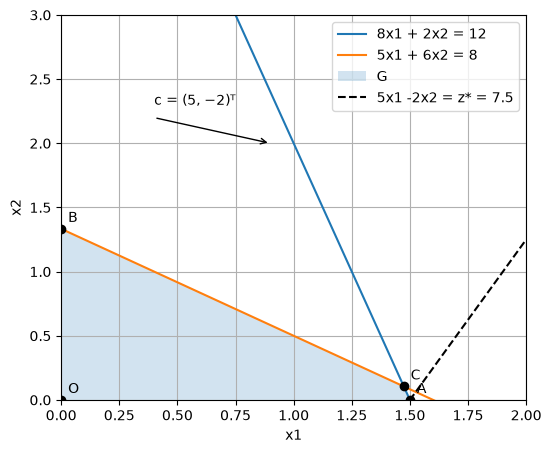

In [2]:
import matplotlib.pyplot as plt

V = np.vstack(table[table["допустимо"]]["X"])               # вершины G
centre = V.mean(axis=0)
V = V[np.argsort(np.arctan2(V[:, 1] - centre[1], V[:, 0] - centre[0]))]

x1 = np.linspace(0, 2, 200)
fig, ax = plt.subplots(figsize=(6, 5))
for i in range(m):
    ax.plot(x1, (b[i] - A[i, 0] * x1) / A[i, 1],
            label=f"{A[i,0]:g}x1 + {A[i,1]:g}x2 = {b[i]:g}")
ax.fill(V[:, 0], V[:, 1], alpha=0.2, label="G")
ax.plot(x1, (z_star - c[0] * x1) / c[1], "k--", label=f"{c[0]:g}x1 {c[1]:+g}x2 = z* = {z_star:g}")
ax.annotate("", xy=(0.4 + 0.1 * c[0], 2.2 + 0.1 * c[1]), xytext=(0.4, 2.2),
            arrowprops=dict(arrowstyle="->"))
ax.text(0.4, 2.3, "c = (5, −2)ᵀ")
for name, key in vertex_name.items():
    pass
for (i, j), nm in vertex_name.items():
    X = table[table["idx"] == (i, j)]["X"].iloc[0]
    ax.plot(*X, "ko"); ax.annotate(nm, X, textcoords="offset points", xytext=(5, 5))
ax.set_xlim(0, 2); ax.set_ylim(0, 3)
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(True)
plt.show()

## Часть 2. Симплекс-метод

### Алгоритм
1. **Каноническая форма**: добавить $s_i=b_i-a_i^TX\ge 0$:
   $$c^TX\to\max,\quad AX+s=b,\quad X\ge 0,\ s\ge 0.$$
   Начальный базис — $s_1,\dots,s_m$; начальное решение $X=0$, $s=b$
   (вершина $O$). Оно допустимо, так как $b\ge 0$.
2. Выразить $z$ через небазисные переменные:
   $z=z_0+\sum_{j\in N}\Delta_j v_j$. Числа $\Delta_j$ (оценки) хранятся в
   последней строке симплекс-таблицы. Если $\Delta_j>0$, рост переменной
   $v_j$ увеличивает $z$.
3. **Критерий оптимальности:** все $\Delta_j\le 0$ — текущая вершина
   оптимальна, конец.
4. Иначе выбрать вводимую переменную с наибольшим $\Delta_j>0$ (столбец $j$).
5. Если в столбце $j$ нет положительных элементов, то $z\to+\infty$ вдоль
   ребра (исход «нет конечного оптимума»), конец.
6. Выводимая переменная — строка $r$ с минимальным отношением
   $\theta_i=\dfrac{b_i}{a_{ij}}$ по $a_{ij}>0$ (это ограничение, которое
   первым станет активным).
7. Сделать элементарные преобразования строк (метод Гаусса) так, чтобы
   столбец $j$ стал единичным; перейти к соседнему базисному решению
   (соседней вершине) и вернуться к шагу 3.

Геометрически каждая итерация — переход по ребру $G$ в соседнюю вершину с
большим значением $z$.

In [9]:
def show_tableau(T, basis, var, it):
    idx = [var[k] for k in basis] + ["Δ"]
    df = pd.DataFrame(T, index=idx, columns=var + ["b"])
    print(f"\nИтерация {it}  (в строке Δ последний элемент равен −z):")
    display(df.round(4))


def solve_by_simplex(c, A, b, verbose=True):
    """Симплекс-метод для c^T X -> max, AX <= b, X >= 0 (требуется b >= 0)."""
    m, n = A.shape
    N = n + m                                       
    assert np.all(b >= 0), "нужна допустимая начальная вершина X = 0 (b >= 0)"
    var = [f"x{j+1}" for j in range(n)] + [f"s{i+1}" for i in range(m)]

    T = np.zeros((m + 1, N + 1))
    T[:m, :n] = A
    T[:m, n:N] = np.eye(m)
    T[:m, N] = b
    T[m, :n] = c
    basis = list(range(n, N))                      

    path, it = [], 0                                
    while True:
        v = np.zeros(N)
        v[basis] = T[:m, N]                         
        path.append(v[:n].copy())
        if verbose:
            show_tableau(T, basis, var, it)

        delta = T[m, :N]
        if np.all(delta <= eps):                    
            break
        j = int(np.argmax(delta))                   
        col = T[:m, j]
        if np.all(col <= eps):                      
            raise ValueError("z не ограничена сверху на G: z -> +∞")

        ratios = np.full(m, np.inf)                 
        pos = col > eps
        ratios[pos] = T[:m, N][pos] / col[pos]
        r = int(np.argmin(ratios))                  
        if verbose:
            print(f"  вводим {var[j]}, выводим {var[basis[r]]}, θ = {fmt(ratios[r])}")

        T[r] /= T[r, j]                             
        for i in range(m + 1):
            if i != r:
                T[i] -= T[i, j] * T[r]
        basis[r] = j
        it += 1

    return v, float(-T[m, N]), path, it             


v, z_simplex, path, iters = solve_by_simplex(c, A, b)
X_simplex, s_simplex = v[:n], v[n:]
print(f"\nX* = ({', '.join(fmt(x) for x in X_simplex)}),  "
      f"s* = ({', '.join(fmt(s) for s in s_simplex)}),  z* = {fmt(z_simplex)}")
print("Пройденные вершины:", [tuple(fmt(x) for x in p) for p in path])


Итерация 0  (в строке Δ последний элемент равен −z):


,x1,x2,s1,s2,b
s1,8.0,2.0,1.0,0.0,12.0
s2,5.0,6.0,0.0,1.0,8.0
Δ,5.0,-2.0,0.0,0.0,0.0


  вводим x1, выводим s1, θ = 1.5

Итерация 1  (в строке Δ последний элемент равен −z):


,x1,x2,s1,s2,b
x1,1.0,0.25,0.125,0.0,1.5
s2,0.0,4.75,-0.625,1.0,0.5
Δ,0.0,-3.25,-0.625,0.0,-7.5



X* = (1.5, 0),  s* = (0, 0.5),  z* = 7.5
Пройденные вершины: [('0', '0'), ('1.5', '0')]


### Результат части 2
- **Итерация 0:** базис $(s_1,s_2)$, вершина $O=(0,0)$, $z=0$. Оценки
  $\Delta=(5,\,-2,\,0,\,0)$: положительна только $\Delta_1$, вводим $x_1$.
  Отношения $12/8=1.5$ и $8/5=1.6$; минимум $1.5$, выводим $s_1$
  (ограничение $a_1^TX\le b_1$ становится активным).
- **Итерация 1:** базис $(x_1,s_2)$, вершина $A=(1.5,\,0)$, $z=7.5$.
  Выражение $z=7.5-3.25\,x_2-0.625\,s_1$: все $\Delta_j\le 0$, критерий
  оптимальности выполнен.

**Ответ:** $X^*=(1.5,\ 0)$, $s^*=(0,\ 0.5)$, $z^*=7.5$. Первое
ограничение активно ($s_1=0$), второе неактивно ($s_2=0.5>0$: остаток
второго ресурса). Симплекс-метод прошёл путь $O\to A$ за одну итерацию.

In [10]:
def compare(c, A, b, title):
    m, n = A.shape
    opt, z1, tab = solve_by_vertex_enumeration(c, A, b)
    v, z2, path, it = solve_by_simplex(c, A, b, verbose=False)
    X1, X2 = opt["X"].iloc[0], v[:n]
    assert np.allclose(X1, X2) and abs(z1 - z2) < 1e-9, "методы дали разные ответы"

    total = len(list(itertools.combinations(range(m + n), n)))
    print(f"=== {title} ===")
    display(pd.DataFrame({
        "метод": ["перебор вершин", "симплекс-метод"],
        "X*": [f"({', '.join(fmt(x) for x in X1)})"] * 2,
        "z*": [fmt(z1), fmt(z2)],
        "что просмотрено": [
            f"{len(tab)} пересечений границ (из C({m+n},{n})={total}), "
            f"допустимых вершин: {int(tab['допустимо'].sum())}",
            f"{it} итераций, вершин посещено: {len(path)}",
        ],
    }))


compare(c, A, b, "Вариант 4")

# Проверка на примере Лекции 
compare(np.array([3.0, 2.0]), np.array([[1.0, 1.0], [2.0, 1.0]]), np.array([4.0, 5.0]),
        "Пример лекции")

=== Вариант 4 ===


,метод,X*,z*,что просмотрено
0,перебор вершин,"(1.5, 0)",7.5,"6 пересечений границ (из C(4,2)=6), допустимых..."
1,симплекс-метод,"(1.5, 0)",7.5,"1 итераций, вершин посещено: 2"


=== Пример лекции ===


,метод,X*,z*,что просмотрено
0,перебор вершин,"(1, 3)",9,"6 пересечений границ (из C(4,2)=6), допустимых..."
1,симплекс-метод,"(1, 3)",9,"2 итераций, вершин посещено: 3"


## Заключение

Задача варианта 4 $z=5x_1-2x_2\to\max$ при $8x_1+2x_2\le 12$,
$5x_1+6x_2\le 8$, $x_1,x_2\ge 0$ решена двумя способами; оба дали один и
тот же результат:
$$X^*=(1.5,\ 0),\qquad z^*=7.5.$$
Оптимум достигается в вершине $A$ и единственен. Так как $c_2<0$,
увеличение $x_2$ только уменьшает $z$, поэтому оптимальная вершина лежит
на оси $x_1$. Оба алгоритма проверены на примере лекции: получено
$X^*=(1,3)$, $z^*=9$.

**Сравнение способов.**

| | Перебор вершин | Симплекс-метод |
|---|---|---|
| Идея | найти все вершины $G$, сравнить $z$ (теорема об оптимальной вершине) | двигаться по соседним вершинам, увеличивая $z$ |
| Объём работы | $C_{m+n}^{n}$ систем; в задаче 6, допустимых вершин 4 | 1 итерация, 2 вершины |
| Рост с размером | $C_{m+n}^{n}$ растёт экспоненциально ($m=n=20$: около $1.4\cdot10^{11}$ наборов) | обычно намного меньше вершин, но гарантий полиномиальности в худшем случае нет |
| Проверка допустимости | нужна для каждой точки (например, $(1.6,0)$ даёт $z=8$, но $\notin G$) | допустимость сохраняется автоматически: $b\ge 0$, отношения $\theta$ |
| Особые случаи | не требует $b\ge 0$; для существования оптимальной вершины нужна ограниченность $G$ | реализация требует $b\ge 0$ (иначе нужен поиск начальной вершины); неограниченность $z$ выявляется по столбцу без положительных элементов |
| Наглядность | прямая проверка теоремы, полный список вершин | видно, какие ограничения активны ($s_i=0$), и пройденный путь $O\to A$ |

Теорема об оптимальной вершине не
требует полного перебора вершин, а число вершин может быть очень
большим. Перебор годится для малых задач и проверки, симплекс-метод
использует геометрию $G$ и лучше масштабируется.